# Lecture 6: the choice leaves the grid

**ECU44291 Quantitative Macroeconomics, Week 6.**

Two tools the grid was hiding: an **optimiser** (the choice $k'$ can be any number, not a grid point) and **interpolation** (the continuation value $V(k')$ has to be read between grid points). Both go inside value function iteration on the growth model, and the Euler-equation error from Lecture 5 measures what they buy.

This is the complete notebook, and I walk through it in the lecture. Before each code cell there is a question: answer it before you run the cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import minimize_scalar

## Task 1: golden-section search

Maximise $f(x) = 4x^2 e^{-2x}$ on $[0.1, 3]$ without derivatives. Write `golden_section(f, a, b, tol)`: two interior points at the golden ratio, keep the half that contains the higher one, reuse the surviving interior point. Return the maximiser and the list of brackets. Compare to `minimize_scalar(lambda x: -f(x), bounds=(0.1, 3), method="bounded")`.

**Question before running:** each step multiplies the width of the bracket by 0.618. Starting from a width of 2.9, about how many brackets until the width is below $10^{-8}$?

In [2]:
# SOLUTION
GOLDEN = (np.sqrt(5) - 1) / 2
def profit(x): return 4 * x**2 * np.exp(-2 * x)

def golden_section(f, a, b, tol=1e-8):
    c, d = b - GOLDEN * (b - a), a + GOLDEN * (b - a)
    fc, fd = f(c), f(d)
    brackets = [(a, b)]
    while b - a > tol:
        if fc > fd:
            b, d, fd = d, c, fc
            c = b - GOLDEN * (b - a); fc = f(c)
        else:
            a, c, fc = c, d, fd
            d = a + GOLDEN * (b - a); fd = f(d)
        brackets.append((a, b))
    return 0.5 * (a + b), brackets

x_gs, br = golden_section(profit, 0.1, 3.0)
res = minimize_scalar(lambda x: -profit(x), bounds=(0.1, 3.0), method="bounded")
print(f"golden section: {x_gs:.8f} after {len(br)} brackets; scipy bounded: {res.x:.8f}")

golden section: 1.00000001 after 42 brackets; scipy bounded: 0.99999989


## Task 2: linear interpolation by hand

Write `interp_linear(x, xp, fp)`: find the bracket with `np.searchsorted`, weight the two endpoints, and clamp outside the grid. Check it against `np.interp` on and off the grid. Then evaluate it at `x = 5` when the grid ends at `1`: what comes back, and why is that dangerous inside a value function?

**Question before running:** what number comes back at `x = 5`?

In [3]:
# SOLUTION
def interp_linear(x, xp, fp):
    # x:  the points where we want a value (any numbers, on or off the grid)
    # xp: the grid, sorted ("x-points");  fp: the known values on it, fp[j] = f(xp[j])
    # (the same names, in the same order, as np.interp)
    # make x an array of floats (a number or a list works too), so the maths below runs on every point at once
    x = np.atleast_1d(np.asarray(x, float))
    # 1. find the bracket: i is the grid point just left of x (searchsorted is a fast lookup in the sorted grid;
    #    clip keeps i between 0 and n - 2, so xp[i] and xp[i + 1] both exist)
    i = np.clip(np.searchsorted(xp, x, side="right") - 1, 0, len(xp) - 2)
    # 2. how far across the bracket x sits: 0 at the left end, 1 at the right
    #    3. clip to [0, 1] is clamping: beyond the grid, stay at the last value
    w = np.clip((x - xp[i]) / (xp[i + 1] - xp[i]), 0.0, 1.0)
    # weight the two ends
    return (1 - w) * fp[i] + w * fp[i + 1]

xp = np.linspace(0, 1, 11); fp = np.sin(3 * xp)
xq = np.array([0.05, 0.37, 0.99, 1.7])
# same answers as NumPy's own? allclose: equal up to rounding error (compare floats this way, never with ==)
print(np.allclose(interp_linear(xq, xp, fp), np.interp(xq, xp, fp)))
print("at x = 5 the interpolant returns", interp_linear(5.0, xp, fp), "= f(1): flat beyond the grid")

True
at x = 5 the interpolant returns [0.14112001] = f(1): flat beyond the grid


## Task 3: why not a high-order polynomial?

Interpolate Runge's function $1/(1+25x^2)$ on 11 equispaced nodes in $[-1, 1]$ three ways: piecewise linear, `scipy.interpolate.CubicSpline`, and the degree-10 polynomial through the nodes (`scipy.interpolate.lagrange`). Plot all three against the truth. Which would you put inside a value function iteration, and why?

**Question before running:** which of the three will be furthest from the truth, and where?

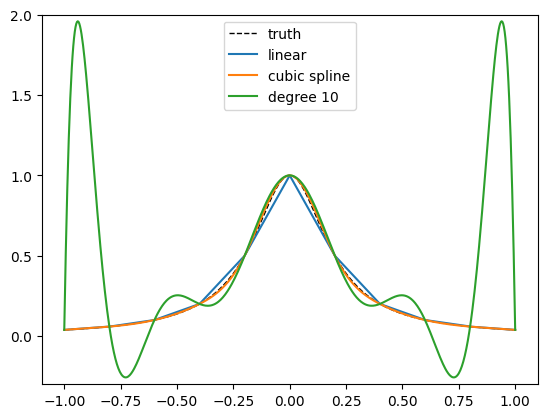

In [4]:
# SOLUTION
from scipy.interpolate import lagrange, CubicSpline
runge = lambda x: 1 / (1 + 25 * x**2)
nodes = np.linspace(-1, 1, 11); xx = np.linspace(-1, 1, 601)
plt.plot(xx, runge(xx), "k--", lw=1, label="truth")
plt.plot(xx, np.interp(xx, nodes, runge(nodes)), label="linear")
plt.plot(xx, CubicSpline(nodes, runge(nodes))(xx), label="cubic spline")
plt.plot(xx, lagrange(nodes, runge(nodes))(xx), label="degree 10")
plt.ylim(-0.3, 2); plt.legend(); plt.show()

## Task 4: fitted value function iteration

Lecture 4's growth model again ($\alpha = 0.3$, $\beta = 0.9$, log utility, full depreciation), but now $k'$ is continuous. In each sweep, build an interpolant of $V$ once, then for each grid point maximise $\ln(k^\alpha - k') + \beta\,\hat V(k')$ over $k' \in [k_{\min}, \min(k^\alpha, k_{\max})]$ with `minimize_scalar(method="bounded")`. Do it twice: with `np.interp` (linear) and with `scipy.interpolate.PchipInterpolator` (a smooth, shape-preserving cubic). For each, report the share of policy values that sit exactly on a grid point, and the maximum distance from the closed form $\alpha\beta k^\alpha$. Time both.

**Question before running:** the choice is now any number in a bracket. What share of the linear version's choices do you expect to land exactly on a grid point? And how long will each take, against a few milliseconds for the grid version?

linear: 132 sweeps, 3.2 s, 74% of choices on grid nodes, max |policy - closed form| = 0.00384


pchip : 132 sweeps, 2.1 s, 0% of choices on grid nodes, max |policy - closed form| = 0.00004


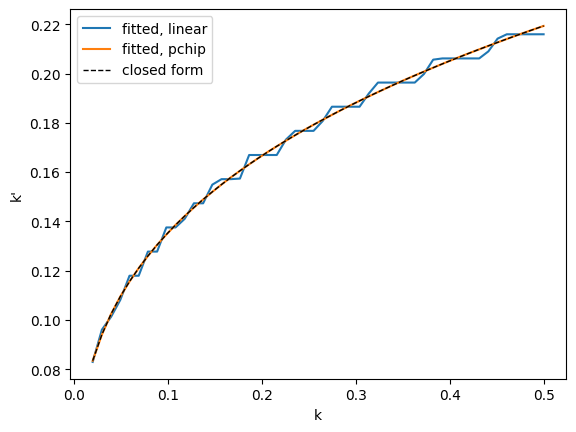

In [5]:
# SOLUTION
from scipy.interpolate import PchipInterpolator
alpha, beta = 0.3, 0.9
k = np.linspace(0.02, 0.5, 50)

def fitted_vfi(kind, tol=1e-6):
    V = np.zeros(len(k))
    for it in range(5000):
        V_hat = PchipInterpolator(k, V) if kind == "pchip" else (lambda x: np.interp(x, k, V))
        TV, pol = np.empty(len(k)), np.empty(len(k))
        for i, ki in enumerate(k):   # one pass per grid point: i is its position, ki = k[i] its value
            y = ki ** alpha
            res = minimize_scalar(lambda kp: -(np.log(y - kp) + beta * V_hat(kp)),
                                  bounds=(k[0], min(y - 1e-10, k[-1])), method="bounded", options={"xatol": 1e-10})
            TV[i], pol[i] = -res.fun, res.x
        if np.max(np.abs(TV - V)) < tol:
            return TV, pol, it + 1
        V = TV

truth = alpha * beta * k**alpha
for kind in ("linear", "pchip"):
    t0 = time.perf_counter(); V, pol, n = fitted_vfi(kind); t = time.perf_counter() - t0
    on_nodes = np.mean(np.min(np.abs(pol[:, None] - k[None, :]), axis=1) < 1e-6)
    print(f"{kind:6s}: {n} sweeps, {t:.1f} s, {on_nodes:.0%} of choices on grid nodes, max |policy - closed form| = {np.max(np.abs(pol - truth)):.5f}")
    plt.plot(k, pol, label=f"fitted, {kind}")
plt.plot(k, truth, "k--", lw=1, label="closed form"); plt.legend(); plt.xlabel("k"); plt.ylabel("k'"); plt.show()

Look at the share on nodes. With a linear interpolant the objective has a kink at every grid point, and a kink is where a concave objective's maximum tends to sit, so the optimiser "snaps" to nodes and the policy is still mostly a staircase. The smooth interpolant has no kinks and the policy lands on the closed form. **The interpolant is part of the method.**

**Workflow note.** *Measure before you optimise.* The fitted sweep is a hundred times slower. Before you touch it, `%time` the inner loop and find out where the time goes.

*NB:* `%time` at the start of a line runs that line and reports how long it took, e.g. `%time V, pol, n = fitted_vfi("linear")`. It works in notebooks only; in a `.py` file, use `time.perf_counter()` before and after, as in the cell above.

## Task 5: Euler-equation errors

The same measure as in Lecture 5. The Euler equation here is $1/c = \beta\alpha k'^{\alpha-1}/c'$. At points *between* grid points (midpoints), compute $c = k^\alpha - g(k)$, $k' = g(k)$, $c' = k'^\alpha - g(k')$ with $g$ interpolated, and the relative error $|1 - c\,\beta\alpha k'^{\alpha-1}/c'|$. Report $\log_{10}$ of the mean for three policies: the grid policy, fitted-linear, fitted-PCHIP. What does a value of $-4$ mean in words?

**Question before running:** in Lecture 5 the grid policy on 50 points scored $-2.10$. What will fitted-linear score? Fitted-PCHIP?

In [6]:
# SOLUTION
def euler_errors(k, policy):
    km = 0.5 * (k[:-1] + k[1:])
    g = lambda x: np.interp(x, k, policy)
    kp = g(km); c = km**alpha - kp; cp = kp**alpha - g(kp)
    return np.log10(np.abs(1 - c * beta * alpha * kp**(alpha - 1) / cp))

cmat = k[:, None]**alpha - k[None, :]; U = np.full(cmat.shape, -np.inf); U[cmat > 0] = np.log(cmat[cmat > 0])
Vd = np.zeros(len(k))
for _ in range(5000):
    val = U + beta * Vd[None, :]; Vn = val.max(1)
    if np.max(np.abs(Vn - Vd)) < 1e-6: Vd = Vn; break
    Vd = Vn
pol_d = k[val.argmax(1)]
_, pol_lin, _ = fitted_vfi("linear")
_, pol_pchip, _ = fitted_vfi("pchip")
for name, pol in (("grid", pol_d), ("fitted linear", pol_lin), ("fitted PCHIP", pol_pchip)):
    print(f"{name:14s}: mean log10 Euler error {euler_errors(k, pol).mean():.2f}")

grid          : mean log10 Euler error -2.10
fitted linear : mean log10 Euler error -2.15
fitted PCHIP  : mean log10 Euler error -3.96


## The household, continuous: the M1 Part C task

The same two tools go inside the life-cycle household's age loop: `minimize_scalar` over $a' \in [0, \min(Ra + y_j, a_{\max})]$ in place of the argmax over the grid, with $V_{j+1}$ interpolated by PCHIP, built once per age. The slide shows what the result looks like. Building it is the M1 Part C task, due with the full submission on Monday 2 November at 09:00, so there is no code for it here.

## Before the next lecture

- **Monday 26 October, 23:59: the `m1-solo` tag.** The grid solver with your two features, your tests, the handwritten derivation and your notes. Nothing in this notebook is needed for it.
- **The study week: M1 Part C.** The continuous choice for your household, with an assistant and a log, and the critique. Keep the grid version: it is the check. Report the share of choices on nodes for both interpolants once, so you have seen the snap yourself, and add the Euler-residual check along the simulated path where the constraint does not bind. The full submission is due Monday 2 November at 09:00.
- Review method cards 4 (golden section) and 5 (linear interpolation).
- Workflow note: the continuous solver is much slower than the grid one. It's worth it to *Measure before you optimise.* to see this `%time` on the inner loop.
- Next lecture, Thursday 5 November: closing the model.